In [1]:
!pip -q install wfdb

In [2]:
import os, glob, ast, random, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

from google.colab import drive
drive.mount("/content/drive")

DRIVE   = "/content/drive/MyDrive/cdss_data"
ZIP_DIR = f"{DRIVE}/raw/ptbxl"
PROC    = f"{DRIVE}/processed/ptbxl"
RES     = f"{DRIVE}/results/cvd"
LOCAL   = "/content/ptbxl"          # local disk, wiped when the session ends
for d in [PROC, RES, LOCAL]:
    os.makedirs(d, exist_ok=True)

# Subset size per official split (edit these to grow or shrink the subset)
N_PER_SPLIT = {"train": 5000, "val": 1000, "test": 1500}
print("Zip files found:", glob.glob(f"{ZIP_DIR}/*.zip"))

Mounted at /content/drive
Zip files found: ['/content/drive/MyDrive/cdss_data/raw/ptbxl/ptb-xl-1.0.3.zip']


In [3]:
zips = glob.glob(f"{ZIP_DIR}/*.zip")
assert len(zips) == 1, f"Expected exactly one zip in {ZIP_DIR}, found {zips}"
ZIP = zips[0]

if not glob.glob(f"{LOCAL}/**/ptbxl_database.csv", recursive=True):
    r = subprocess.run(["unzip", "-q", "-n", ZIP,
                        "*ptbxl_database.csv", "*scp_statements.csv", "*records100/*",
                        "-d", LOCAL])
    assert r.returncode in (0, 1), "unzip failed"

ROOT = os.path.dirname(glob.glob(f"{LOCAL}/**/ptbxl_database.csv", recursive=True)[0])
n_dat = len(glob.glob(f"{ROOT}/records100/**/*.dat", recursive=True))
print("PTB-XL root:", ROOT)
print("100 Hz recordings found:", n_dat)
assert n_dat == 21799, "Expected 21799 recordings. Re-extract the zip."

PTB-XL root: /content/ptbxl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3
100 Hz recordings found: 21799


In [4]:
# [helpers-labels]
CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]


def build_labels(db, scp):
    """Add superclass list, one 0/1 column per class, and n_labels to the metadata table."""
    db = db.copy()
    diag = scp[scp["diagnostic"] == 1]

    def to_super(codes):
        return sorted({diag.loc[k, "diagnostic_class"] for k in codes if k in diag.index})

    db["superclass"] = db["scp_codes"].apply(to_super)
    for c in CLASSES:
        db[c] = db["superclass"].apply(lambda s: int(c in s))
    db["n_labels"] = db["superclass"].apply(len)
    return db


def fix_age(db, cap=120, replace_with=90):
    """PTB-XL stores some very old patients with an anonymised placeholder age (300). Cap those."""
    db = db.copy()
    n_bad = int((db["age"] > cap).sum())
    db["age"] = db["age"].where(~(db["age"] > cap), replace_with)
    return db, n_bad


def add_split(db):
    db = db.copy()
    db["split"] = np.where(db["strat_fold"] == 10, "test",
                    np.where(db["strat_fold"] == 9, "val", "train"))
    return db

In [5]:
db  = pd.read_csv(f"{ROOT}/ptbxl_database.csv", index_col="ecg_id")
scp = pd.read_csv(f"{ROOT}/scp_statements.csv", index_col=0)
db["scp_codes"] = db["scp_codes"].apply(ast.literal_eval)

db = build_labels(db, scp)
db, n_bad_age = fix_age(db)
db = add_split(db)

print("ECGs:", len(db), "| patients:", db["patient_id"].nunique())
print("ECGs with no diagnostic label:", int((db["n_labels"] == 0).sum()))
print("Ages above 120 replaced with 90:", n_bad_age)
print("Missing age:", int(db["age"].isna().sum()), "| missing sex:", int(db["sex"].isna().sum()))
print()
print(db[CLASSES].sum().rename("ECGs per class"))

ECGs: 21799 | patients: 18869
ECGs with no diagnostic label: 411
Ages above 120 replaced with 90: 293
Missing age: 0 | missing sex: 0

NORM    9514
MI      5469
STTC    5235
CD      4898
HYP     2649
Name: ECGs per class, dtype: int64


In [6]:
folds_per_patient = db.groupby("patient_id")["strat_fold"].nunique()
assert (folds_per_patient == 1).all(), "Some patients appear in more than one fold"
print("OK: every patient is in exactly one fold\n")
print(db["split"].value_counts())

OK: every patient is in exactly one fold

split
train    17418
test      2198
val       2183
Name: count, dtype: int64


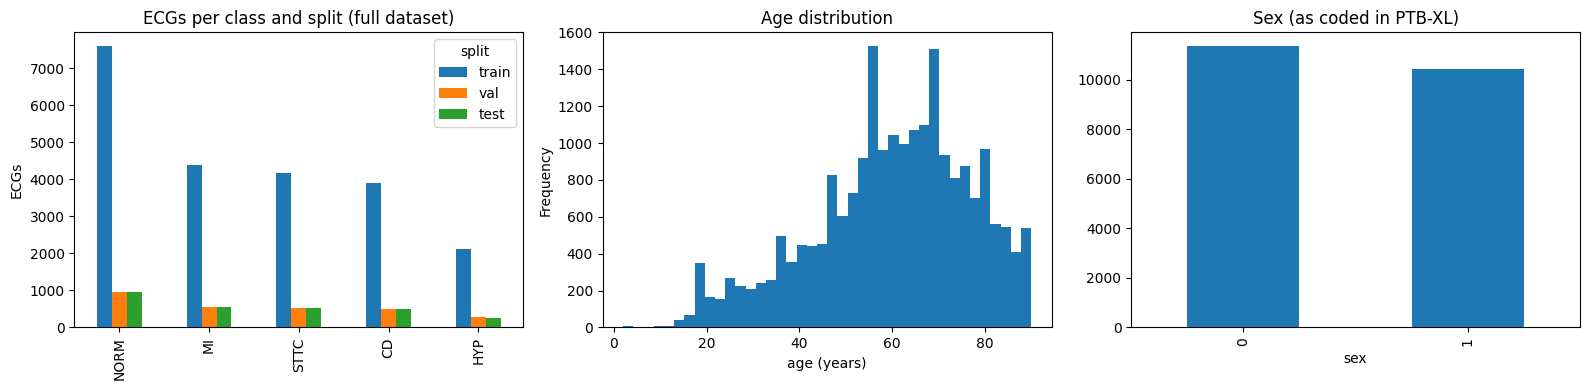

,ECGs,patients,no_label_ECGs,age_mean,age_missing
0,21799,18869,411,59.9,0


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

counts = db.groupby("split")[CLASSES].sum().loc[["train", "val", "test"]]
counts.T.plot.bar(ax=ax[0])
ax[0].set_title("ECGs per class and split (full dataset)")
ax[0].set_ylabel("ECGs")

db["age"].plot.hist(bins=40, ax=ax[1])
ax[1].set_title("Age distribution")
ax[1].set_xlabel("age (years)")

db["sex"].value_counts().sort_index().plot.bar(ax=ax[2])
ax[2].set_title("Sex (as coded in PTB-XL)")
plt.tight_layout()
plt.savefig(f"{RES}/01_eda_overview.png", dpi=150)
plt.show()

eda = pd.DataFrame({
    "ECGs": [len(db)],
    "patients": [db["patient_id"].nunique()],
    "no_label_ECGs": [int((db["n_labels"] == 0).sum())],
    "age_mean": [round(db["age"].mean(), 1)],
    "age_missing": [int(db["age"].isna().sum())],
})
display(eda)
eda.to_csv(f"{RES}/01_ptbxl_eda_summary.csv", index=False)

In [8]:
# [helpers-subset]
def sample_subset(db, n_per_split, seed=42):
    parts = []
    for split, n in n_per_split.items():
        pool = db[(db["split"] == split) & (db["n_labels"] > 0)]
        parts.append(pool.sample(n=min(n, len(pool)), random_state=seed))
    return pd.concat(parts)

In [9]:
sub = sample_subset(db, N_PER_SPLIT, SEED)

# Patients must not cross splits
pat_splits = sub.groupby("patient_id")["split"].nunique()
assert (pat_splits == 1).all(), "A patient appears in more than one split in the subset"

summary = sub.groupby("split")[CLASSES].sum().loc[["train", "val", "test"]]
summary["ECGs"] = sub["split"].value_counts()
display(summary)

# Compare class mix: subset vs full dataset (percent of labeled ECGs carrying each class)
full_mix = db[db["n_labels"] > 0][CLASSES].mean().mul(100).round(1)
sub_mix  = sub[CLASSES].mean().mul(100).round(1)
display(pd.DataFrame({"full_%": full_mix, "subset_%": sub_mix}))
summary.to_csv(f"{RES}/01_subset_summary.csv")

,NORM,MI,STTC,CD,HYP,ECGs
split,,,,,,
train,2269,1234,1215,1138,626,5000
val,452,253,238,228,127,1000
test,665,385,357,345,189,1500


,full_%,subset_%
NORM,44.5,45.1
MI,25.6,25.0
STTC,24.5,24.1
CD,22.9,22.8
HYP,12.4,12.6


In [11]:
# [helpers-signals]
def load_signals(root, rel_paths, n_samples=1000, n_leads=12):
    """Read ECGs with wfdb into one float32 array. Returns array, list of bad indices, NaN count."""
    import wfdb
    X = np.zeros((len(rel_paths), n_samples, n_leads), dtype=np.float32)
    bad, n_nan = [], 0
    for i, p in enumerate(tqdm(rel_paths)):
        try:
            sig, _ = wfdb.rdsamp(f"{root}/{p}")
            if sig.shape != (n_samples, n_leads):
                bad.append(i); continue
            if np.isnan(sig).any():
                n_nan += 1
                sig = np.nan_to_num(sig)
            X[i] = sig
        except Exception:
            bad.append(i)
    return X, bad, n_nan

In [12]:
sub = sub.sort_values(["split"]).copy()
X, bad, n_nan = load_signals(ROOT, sub["filename_lr"].tolist())
print("signal array:", X.shape, "| unreadable:", len(bad), "| recordings with NaN fixed:", n_nan)

if bad:
    keep = np.ones(len(sub), dtype=bool); keep[bad] = False
    sub = sub[keep]; X = X[keep]

# --- FIX 1: Compute imputation statistics strictly on the TRAIN split (no leakage) ---
train_mask = (sub["split"] == "train")
age_median = float(sub.loc[train_mask, "age"].median())
sex_mode   = float(sub.loc[train_mask, "sex"].mode().iloc[0])

Y      = sub[CLASSES].values.astype(np.float32)
age    = sub["age"].fillna(age_median).values.astype(np.float32)
sex    = sub["sex"].fillna(sex_mode).values.astype(np.float32)
split  = sub["split"].values
ecg_id = sub.index.values

# --- FIX 2: Clean report strings & log missingness for downstream ClinicalBERT/BioBERT ---
sub["report_clean"] = sub["report"].fillna("").astype(str).str.strip()
has_report = (sub["report_clean"].str.len() > 0).mean() * 100
print(f"Train age median: {age_median:.1f} | Train sex mode: {sex_mode:.0f} | Non-empty reports: {has_report:.1f}%")

np.savez(f"{PROC}/ptbxl_subset_100hz.npz",
         X=X, Y=Y, age=age, sex=sex, split=split, ecg_id=ecg_id,
         age_median=np.array(age_median, dtype=np.float32),
         sex_mode=np.array(sex_mode, dtype=np.float32),
         classes=np.array(CLASSES))

sub[["patient_id", "age", "sex", "strat_fold", "split", "filename_lr", "report", "report_clean"] + CLASSES] \
    .to_csv(f"{PROC}/ptbxl_subset_meta.csv")
print("saved to", PROC)
print("file size (MB):", round(os.path.getsize(f"{PROC}/ptbxl_subset_100hz.npz") / 1e6))

  0%|          | 0/7500 [00:00<?, ?it/s]

signal array: (7500, 1000, 12) | unreadable: 0 | recordings with NaN fixed: 0
Train age median: 61.0 | Train sex mode: 0 | Non-empty reports: 100.0%
saved to /content/drive/MyDrive/cdss_data/processed/ptbxl
file size (MB): 360


{'X': (7500, 1000, 12), 'Y': (7500, 5), 'age': (7500,), 'sex': (7500,), 'split': (7500,), 'ecg_id': (7500,)}
Saved train age_median: 61.0 | sex_mode: 0.0
signal mean/std: -0.0007591337780468166 0.23956480622291565


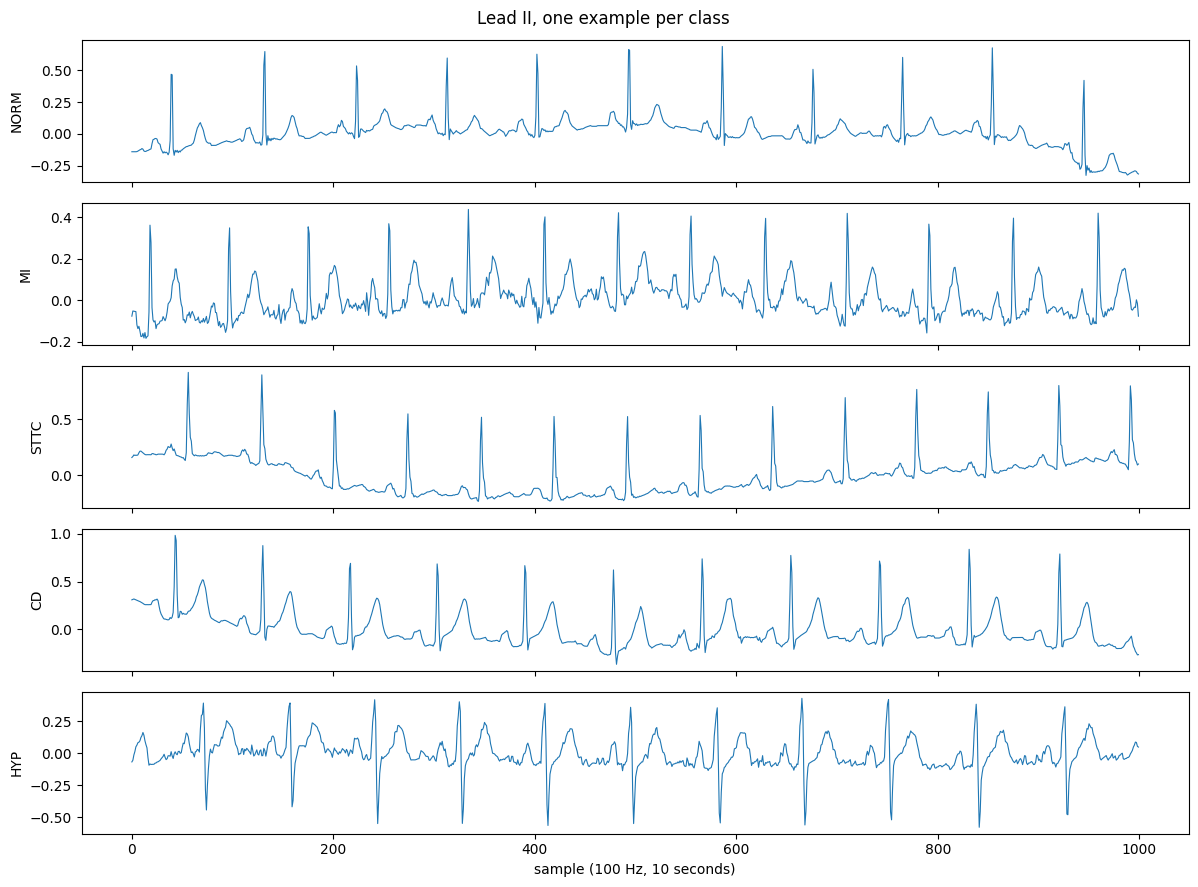

In [13]:
d = np.load(f"{PROC}/ptbxl_subset_100hz.npz", allow_pickle=True)
print({k: d[k].shape for k in ["X", "Y", "age", "sex", "split", "ecg_id"]})
print("Saved train age_median:", float(d["age_median"]), "| sex_mode:", float(d["sex_mode"]))
print("signal mean/std:", float(d["X"].mean()), float(d["X"].std()))
assert not np.isnan(d["X"]).any()
assert not np.isnan(d["age"]).any()

fig, axes = plt.subplots(len(CLASSES), 1, figsize=(12, 9), sharex=True)
for ax, (j, c) in zip(axes, enumerate(CLASSES)):
    idx = np.where((d["Y"][:, j] == 1) & (d["Y"].sum(1) == 1))[0]
    i = idx[0] if len(idx) else np.where(d["Y"][:, j] == 1)[0][0]
    ax.plot(d["X"][i][:, 1], lw=0.8)
    ax.set_ylabel(c)
axes[-1].set_xlabel("sample (100 Hz, 10 seconds)")
plt.suptitle("Lead II, one example per class")
plt.tight_layout()
plt.savefig(f"{RES}/01_example_ecgs.png", dpi=150)
plt.show()